Shape: (150, 4)


C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window


 k | Inertia (WCSS)
 1 | 600.00
 2 | 222.36
 3 | 139.82
 4 | 114.09
 5 | 90.93
 6 | 81.54
 7 | 72.63
 8 | 62.54
 9 | 55.12
10 | 47.39


C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Window


 k | Silhouette
 2 | 0.5818
 3 | 0.4599
 4 | 0.3869
 5 | 0.3459
 6 | 0.3171
 7 | 0.3202
 8 | 0.3387
 9 | 0.3424
10 | 0.3518

Optimal k (Elbow) = 3 | Highest silhouette at k = 2
Cluster sizes: {0: 53, 1: 50, 2: 47}

Clusters vs true species (validation only):
species  setosa  versicolor  virginica
cluster                               
0             0          39         14
1            50           0          0
2             0          11         36


C:\Users\kulde\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1428: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


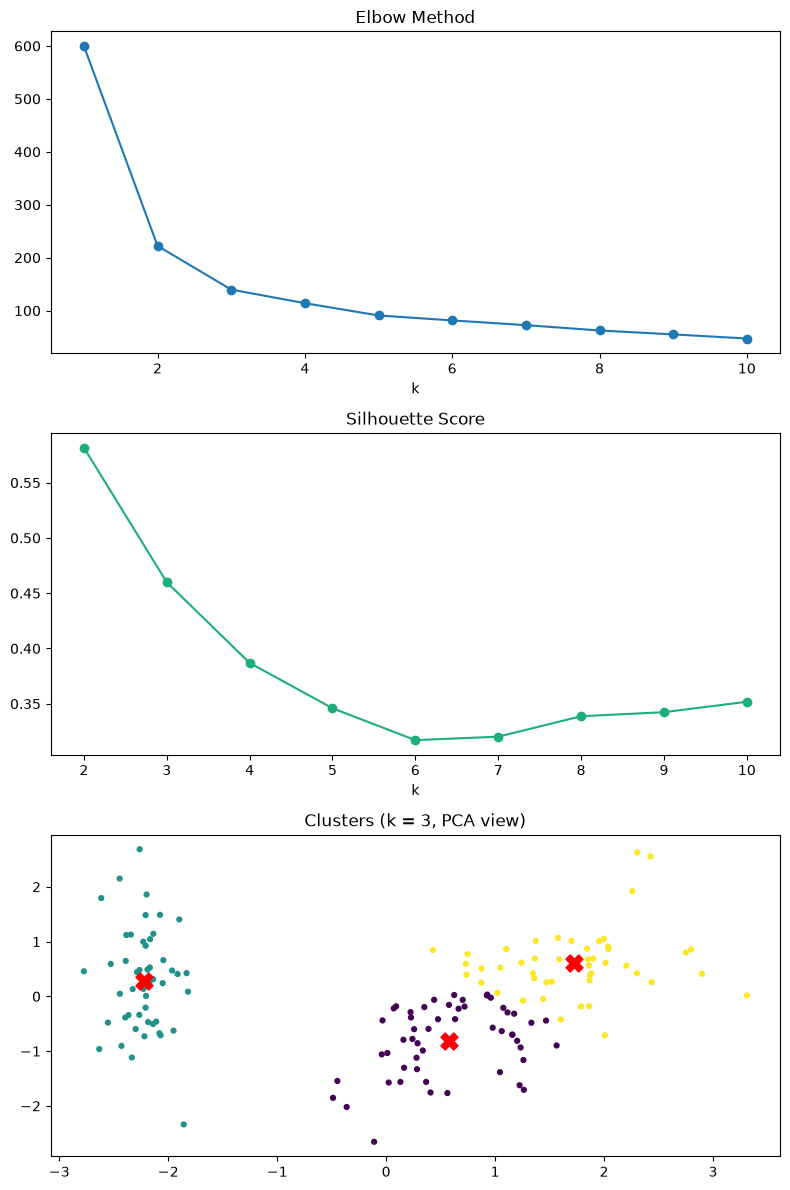

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
iris = load_iris()
X = StandardScaler().fit_transform(iris.data) # species label NOT used for clustering
print("Shape:", X.shape)
# Elbow method
inertia = [KMeans(n_clusters=k, n_init=10, random_state=42).fit(X).inertia_ for k in range(1, 11)]
print("\n k | Inertia (WCSS)")
for k, v in zip(range(1, 11), inertia): print("%2d | %.2f" % (k, v))
# Silhouette method
sil = {k: silhouette_score(X, KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(X)) for k in range(2,
11)}
print("\n k | Silhouette")
for k, v in sil.items(): print("%2d | %.4f" % (k, v))
k_opt = 3 # elbow at k = 3
km = KMeans(n_clusters=k_opt, n_init=10, random_state=42).fit(X)
print("\nOptimal k (Elbow) = 3 | Highest silhouette at k =", max(sil, key=sil.get))
print("Cluster sizes:", pd.Series(km.labels_).value_counts().sort_index().to_dict())
print("\nClusters vs true species (validation only):")
print(pd.crosstab(km.labels_, iris.target_names[iris.target], rownames=["cluster"], colnames=["species"]))
Z = PCA(2).fit(X); P = Z.transform(X); C = Z.transform(km.cluster_centers_)
fig, ax = plt.subplots(3, 1, figsize=(8, 12))
ax[0].plot(range(1, 11), inertia, "o-"); ax[0].set_title("Elbow Method"); ax[0].set_xlabel("k")
ax[1].plot(list(sil), list(sil.values()), "o-", color="#1baf7a"); ax[1].set_title("Silhouette Score");
ax[1].set_xlabel("k")
ax[2].scatter(P[:, 0], P[:, 1], c=km.labels_, cmap="viridis", s=12)
ax[2].scatter(C[:, 0], C[:, 1], marker="X", s=150, color="red"); ax[2].set_title("Clusters (k = 3, PCA view)")
plt.tight_layout()